# Jobs 51223007 and 51246202 — the attention-only width ladder at L=12

Stage E left the standing minimum at **attention-only `L=12 d256`**, 3,331,642
trainable at `rho_50` 0.605: depth bought back everything removing the MLP cost.
The question it left open is whether that saving **composes** — if depth is
doing the MLP's work, can the model also be made narrow? — or whether width is a
second, independent floor.

**Stage H (`51223007`, 6/6)** asked it at `d128` and `d192`. `d192` trained on
3 of 3 seeds and landed at `rho_50` 0.754. `d128` escaped finding 44's 1.64
plateau on only **1 of 3** seeds, so H's registered trainability gate fired and
its (D)/(W) call came back **INCONCLUSIVE** — a rung that did not train cannot
be read as a rung that cannot represent the task.

**Stage I (`51246202`, 3/3)** put `d160` in the gap. It trained on 3 of 3 and
came in at `rho_50` 0.773, so the trainability floor is **GRADED, not a cliff**,
and the bracket closes to [128, 160].

**The ladder, and the result.**

| d_model | rho_50 | crossing | escapes | trainable |
|---|---|---|---|---|
| 128 (H1) | CENSORED | 1/3 | 1/3 | 879,418 |
| 160 (I1) | 0.773 | 3/3 | 3/3 | 1,345,018 |
| 192 (H2) | 0.754 | 3/3 | 3/3 | 1,908,922 |
| 256 (E2) | 0.605 | 3/3 | 3/3 | 3,331,642 |

Only the top step is separable against the frozen bar `s*` = 0.1484: d160→d192
is 0.13 s\*, d192→d256 is 1.00 s\*. **Width is a second floor and it sits
between d192 and d256.** No improvement is claimed — the standing minimum is
unchanged, and that negative is the point.

Everything below is scored by `scripts/stageh_score.py` and
`scripts/stagei_score.py`, both committed before their arrays closed. This
notebook runs them; it does not restate their conclusions in its own words.
Section 6 gives `rho_50` against the previous best on the same eval.

In [1]:
import json, os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

REPO = "/home/users/hshunt/spin_gnn"
BOOT = 2000          # the programme's scoring default; CIs here match the scorers'
SEEDS = (0, 1, 2)    # every rung here is 3 seeds

from scripts.minarch_analysis import SCAN_DIRS, SCAN_E, SCAN_G, SCAN_H, SCAN_I
from scripts.stagec_score import HUB, PLATEAU, S_RHO50, S_MEAN, escapes, rho_txt, rung, summarize
from scripts.stageh_score import FREE, HUB_RHO50, LOO_BAR, PRED_ESCAPES_HEADER, PRED_ESCAPES_Q3
from scripts.stagei_score import (BRACKET_AT_REGISTRATION, E2, H1, H2, I1, L6_D128,
                                  PRED_NLL_LO, PRED_NLL_HI)
from scripts.stagei_score import PREDICTED_TRAINABLE as PRED_TR_I
from scripts.stageh_score import PREDICTED_TRAINABLE as PRED_TR_H
from notebooks.make_stagehi_deck import (FULL_L12, LADDER, collect, curve, ladder_rows,
                                         steps, sufficiency)

# SCAN_H and SCAN_I are read here and HAVE to be -- they are the subject. They
# stay out of SCAN_DIRS, and so out of every other notebook, because their rungs
# would pool into the s* that stages A-F were already scored against. s* is
# quoted frozen below and never recomputed.
DIRS = SCAN_DIRS + [SCAN_E, SCAN_G, SCAN_H, SCAN_I]

COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=REPO,
                        capture_output=True, text=True).stdout.strip()
print("git commit        ", COMMIT)
print("branch            ", subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"],
                                           cwd=REPO, capture_output=True,
                                           text=True).stdout.strip())
print("bootstrap draws   ", BOOT)
print("frozen yardstick  ", f"s* = {S_RHO50} in rho_50, {S_MEAN} in mean_solve")
print("plateau           ", f"train NLL {PLATEAU} (finding 44)")
print("free line         ", f"rho_50 <= {FREE} (hub {HUB_RHO50} + s*)")
print("sufficiency bar   ", f"leave-one-out RMS {LOO_BAR}")
print("scan dirs         ", len(DIRS), "dirs; subjects are",
      os.path.basename(SCAN_H), "and", os.path.basename(SCAN_I))

git commit         cd5e731
branch             sudoku-dd
bootstrap draws    2000
frozen yardstick   s* = 0.1484 in rho_50, 0.2918 in mean_solve
plateau            train NLL 1.64 (finding 44)
free line          rho_50 <= 0.74 (hub 0.592 + s*)
sufficiency bar    leave-one-out RMS 0.0423
scan dirs          8 dirs; subjects are sudoku_n48_minarch_H_2026-11-05 and sudoku_n48_minarch_I_2026-11-05


## 1. Provenance: one knob, asserted rather than assumed

Read off each cell's `config.json`, not from the sbatch headers. The four rungs
of the ladder must differ in `d_model` and in **nothing else** — not in depth,
not in `dim_feedforward`, not in `nhead`, not in `arch_mode`, not in the
learning rate, the pool or the seeds. A difference anywhere else and the ladder
is not a ladder.

The parameter counts are the other half of the provenance. `4*d^2 + 8*d` per
layer plus `630*d + 58` fixed was registered in each sbatch as an assertion that
aborts before training if the model it builds disagrees, so the counts below are
predictions that held, not descriptions written afterwards.

In [2]:
cells, raw = collect(DIRS, BOOT)
rows = ladder_rows(cells)
print(f"{len(cells)} cells on disk | ladder " + ", ".join(
    f"d{r['d']} {r['s']['n']}/3 seeds" for r in rows) + chr(10))

FIELDS = ("d_model", "num_layers", "dim_feedforward", "nhead", "arch_mode", "epochs",
          "lr", "batch_size", "n_train_instances", "warmup_epochs", "shuffle_adj", "fall",
          "n_nodes", "degree", "n_colors")
print(f"{'rung':<22}" + "".join(f"{f.replace('_', ' ')[:11]:>13}" for f in FIELDS[:5]))
print("-" * 87)
base = None
for r in rows:
    cfg = json.load(open(os.path.join(r["ms"][0]["path"], "config.json")))
    print(f"{r['tag'] + '  d' + str(r['d']) + ', stage ' + r['stage']:<22}"
          + "".join(f"{str(cfg.get(f)):>13}" for f in FIELDS[:5]))
    base = base or cfg

print()
for r in rows:
    for m in r["ms"]:
        a = json.load(open(os.path.join(m["path"], "config.json")))
        # solve_metrics is the eval RESULT, written back into config.json by the
        # runner; out_dir/run_name carry the task index. Neither is an input.
        diff = sorted(k for k in set(a) | set(base) if a.get(k) != base.get(k)
                      and k not in ("out_dir", "run_name", "d_model", "seed", "solve_metrics"))
        print(f"  d{r['d']} seed {a['seed']}: fields differing from the d{rows[0]['d']} "
              f"config besides d_model and seed: {diff or 'NONE'}")
print("  (baseline_accuracy and n_trainable_params are written back into config.json by the")
print("   runner -- they are outputs of the cell, not inputs to it. No INPUT differs.)")
print()
print("held constant across all 12 cells:",
      "  ".join(f"{f}={base.get(f)}" for f in FIELDS[5:]))

print()
print("PARAMETER COUNTS -- registered formula vs what the model actually built")
print(f"  {'rung':<12}{'predicted':>12}{'observed':>12}   formula 4*d^2+8*d per layer, 630*d+58 fixed")
print("  " + "-" * 76)
PRED = {128: PRED_TR_H["H1"], 160: PRED_TR_I["I1"], 192: PRED_TR_H["H2"]}
for r in rows:
    d = r["d"]
    want = PRED.get(d, 12 * (4 * d * d + 8 * d) + 630 * d + 58)
    got = r["s"]["trainable"]
    print(f"  d{d:<11}{want:>12,}{got:>12,}   {'ok' if want == got else 'MISMATCH'}"
          f"{'  (registered in the sbatch)' if d in PRED else '  (formula, stage E rung)'}")

93 cells on disk | ladder d128 3/3 seeds, d160 3/3 seeds, d192 3/3 seeds, d256 3/3 seeds

rung                        d model   num layers  dim feedfor        nhead    arch mode
---------------------------------------------------------------------------------------
H1  d128, stage H               128           12         1024            4       no_mlp
I1  d160, stage I               160           12         1024            4       no_mlp
H2  d192, stage H               192           12         1024            4       no_mlp
E2  d256, stage E               256           12         1024            4       no_mlp

  d128 seed 0: fields differing from the d128 config besides d_model and seed: NONE
  d128 seed 1: fields differing from the d128 config besides d_model and seed: ['baseline_accuracy']
  d128 seed 2: fields differing from the d128 config besides d_model and seed: ['baseline_accuracy']
  d160 seed 0: fields differing from the d128 config besides d_model and seed: ['n_trainable_pa

## 2. The metrics table

`rho_50` is the realized hint density at which the solve rate crosses 0.5 on a
14-point × 400-instance leak-free grid (`--shuffle-adj --fall`), **lower is
better**, reported CENSORED when no bin crosses. `mean_solve` is the unweighted
mean over the 14 bins and never censors, which is why a censored rung still has
a readable number. `spread` is the seed-to-seed range in `mean_solve`, against
the frozen bar `s*` = 0.2918 on that metric.

Medians are compared to medians, three seeds per rung, and a censored seed is
ordered above every seed that crossed — enough to make the median well defined
whenever the middle rank is finite.

In [3]:
print(f"  {'rung':<20}{'rho_50':>10}{'mean_solve':>12}{'spread':>9}{'cross':>8}{'esc':>6}"
      f"{'tok acc':>10}{'train NLL':>11}{'trainable':>12}")
print("  " + "-" * 98)
for r in rows:
    s = r["s"]
    print(f"  {r['tag'] + '  no_mlp L=12 d' + str(r['d']):<20}{rho_txt(s):>10}"
          f"{s['mean_solve']:>12.4f}{s['spread_mean']:>9.4f}{s['n_cross']:>5}/{s['n']}"
          f"{r['esc']:>4}/{s['n']}{r['acc']:>10.4f}{sorted(r['nll'])[1]:>11.4f}"
          f"{s['trainable']:>12,}")

print()
print("  per-seed final train NLL, and which seeds left the plateau")
for r in rows:
    marks = "  ".join(f"s{i} {v:.4f}{'*' if v < PLATEAU else ' '}"
                      for i, v in enumerate(r["nll"]))
    print(f"    d{r['d']:<4} {marks}      (* = below the {PLATEAU} plateau)")

print()
print("  CONSECUTIVE STEPS UP THE LADDER, against the frozen bar")
for a, b, gap, units in steps(rows):
    verdict = "separable" if units >= 1.0 else "NOT separable at this bar"
    print(f"    d{a} -> d{b}: rho_50 {gap:+.3f}  = {units:.2f} s*   {verdict}")
print(f"    d128 -> d160 cannot be read: d128 is censored, so its rho_50 is only known")
print(f"    to be somewhere above the top of the grid.")

  rung                    rho_50  mean_solve   spread   cross   esc   tok acc  train NLL   trainable
  --------------------------------------------------------------------------------------------------
  H1  no_mlp L=12 d128  CENSORED      0.0411   0.2729    1/3   1/3    0.4607     1.6703     879,418
  I1  no_mlp L=12 d160     0.773      0.3000   0.0164    3/3   3/3    0.4818     1.6067   1,345,018
  H2  no_mlp L=12 d192     0.754      0.3220   0.1450    3/3   3/3    0.4851     1.5632   1,908,922
  E2  no_mlp L=12 d256     0.605      0.5214   0.0480    3/3   3/3    0.4926     1.5372   3,331,642

  per-seed final train NLL, and which seeds left the plateau
    d128  s0 1.6768   s1 1.6703   s2 1.6235*      (* = below the 1.64 plateau)
    d160  s0 1.6067*  s1 1.5700*  s2 1.6137*      (* = below the 1.64 plateau)
    d192  s0 1.5632*  s1 1.5717*  s2 1.5511*      (* = below the 1.64 plateau)
    d256  s0 1.5372*  s1 1.5243*  s2 1.5374*      (* = below the 1.64 plateau)

  CONSECUTIVE STEPS

## 3. The registered scorers, run verbatim

`scripts/stageh_score.py` was committed (`a4a6405`) before the first stage H
cell landed; `scripts/stagei_score.py` (`c5a1009`) before the first stage I cell
landed. Both are run here as subprocesses so the words in this notebook and on
the slides can be checked against the words the scorers print.

Stage I's scorer also carries a **bracket control**: it records the state of
d128 and d192 *as they stood when the prediction was registered*, so the
interpolation that produced the [1.600, 1.620] train-NLL interval cannot be
reread favourably after the fact. It reports that d192 had only 1 of 3 cells
finished at that moment, and that cell was still descending.

In [4]:
for mod in ("scripts.stageh_score", "scripts.stagei_score"):
    r = subprocess.run([sys.executable, "-m", mod], cwd=REPO, capture_output=True, text=True)
    print("=" * 100)
    print(f"$ python3 -m {mod}")
    print("=" * 100)
    print(r.stdout)
    if r.returncode != 0:
        print("STDERR:", r.stderr[-2000:])

$ python3 -m scripts.stageh_score
STAGE H: does the depth that bought the MLP back survive being made NARROW?
  84 cells read; ONE knob from E2, d_model 256 -> 192 and 128
  frozen bar s* = 0.1484 rho_50 / 0.2918 mean_solve, NOT recomputed
  (D) H1 <= 0.74 on >= 2 of 3 crossing seeds; (W) H1 in [0.72, 0.8] or censored; [0.72, 0.74] scores as (W)

FROZEN-LITERAL CONTROL (the paired partners, re-read from disk):
  E2 matches the frozen literals
  L6_D128 matches the frozen literals

=== H2 -- THE BISECTOR, attention-only L=12 d192 ===
  3/3 seeds on disk, 3/3 crossed 0.5
  rho_50 median     0.754   (hub 0.592, E2 0.605, free at or below 0.74)
  mean_solve       0.3220   [spread 0.1450]   (E2 0.5214)
  trainable 1,908,922   (header arithmetic 1,908,922)
  plateau escapes 3/3   train NLL 1.563/1.572/1.551

=== H1 -- THE CHEAP END, attention-only L=12 d128 ===
  3/3 seeds on disk, 1/3 crossed 0.5
  rho_50 median  CENSORED   (hub 0.592, E2 0.605, free at or below 0.74)
  mean_solve       0.0

## 4. The figures, as they appear on the slides

Drawn by importing the deck module, so the notebook and the PDF cannot drift.
The first is the ladder: every seed, not just the median, with the censored
seeds as open triangles at the grid edge because that is all the eval knows
about them. The second is the training curves — nine cells, one plateau line,
and the three stalled d128 seeds in grey.

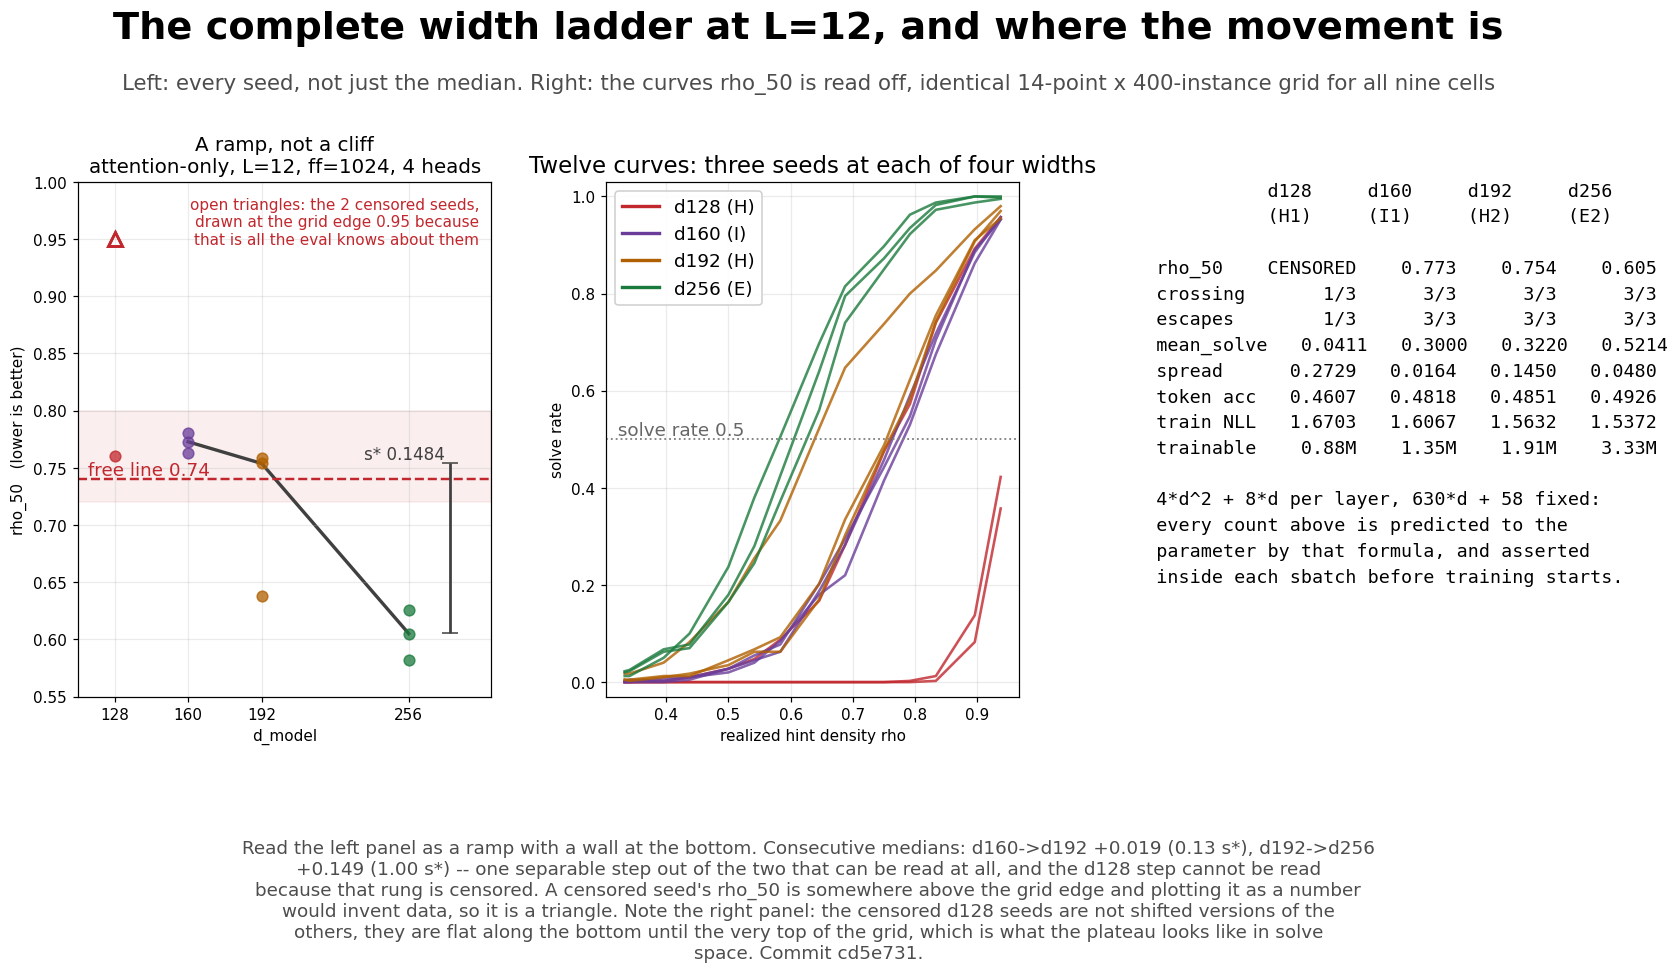

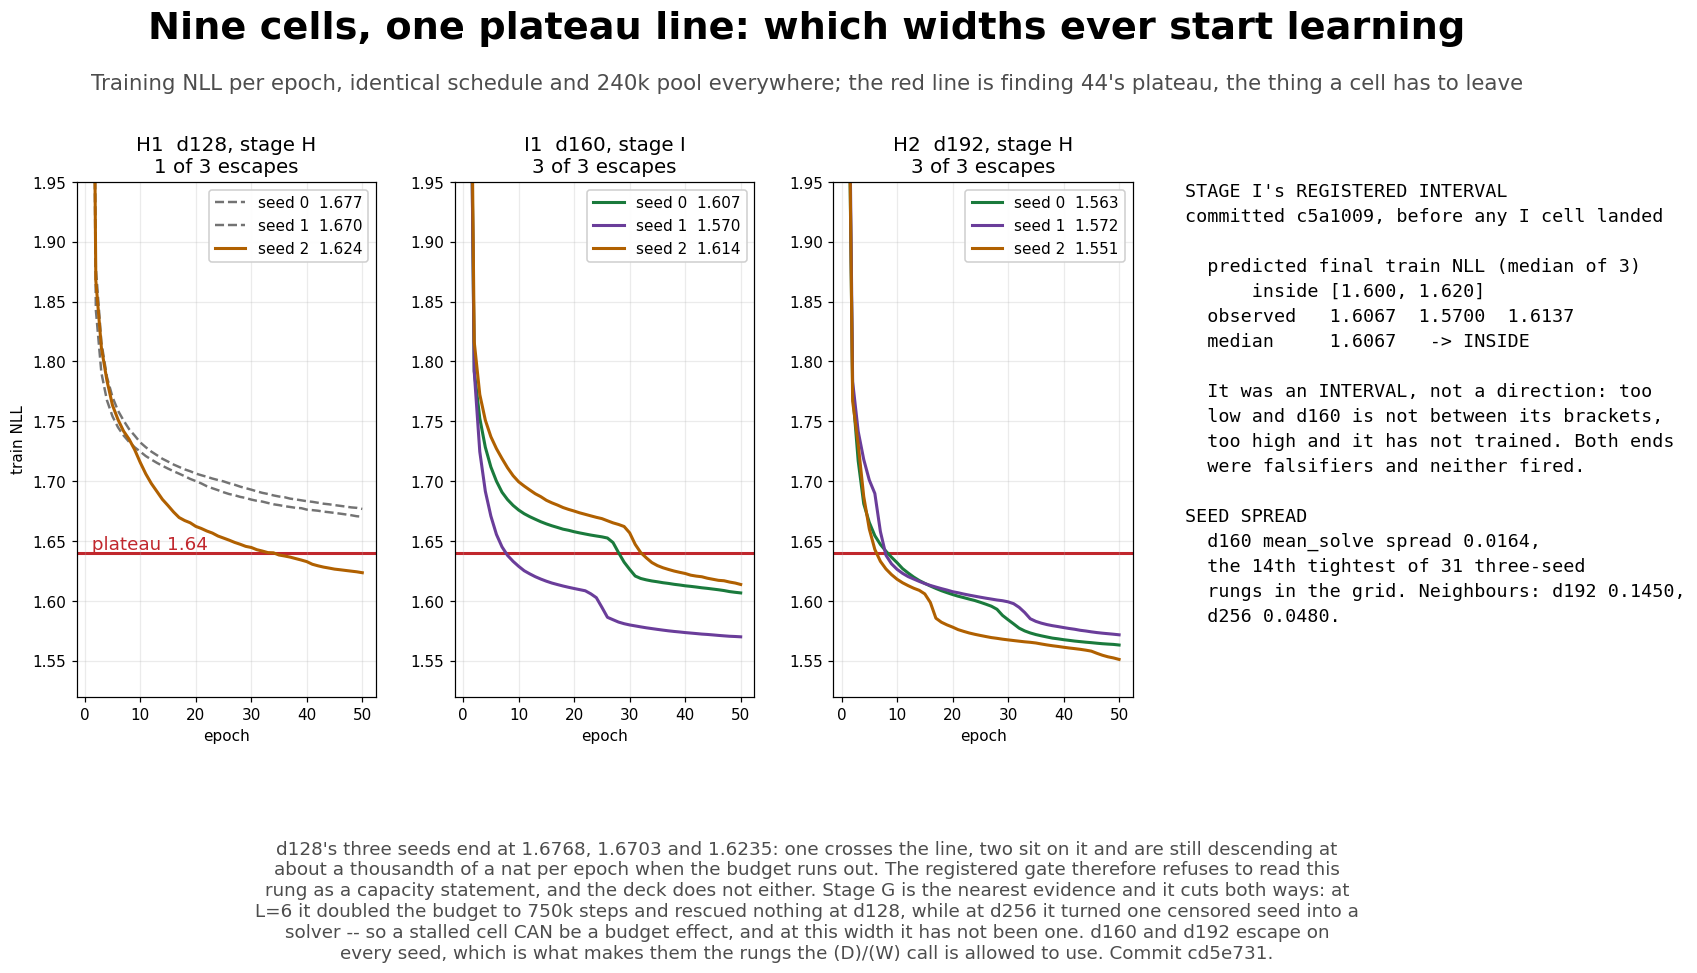

In [5]:
from notebooks.make_stagehi_deck import page_ladder, page_training


class Keep:
    """A PdfAndPng stand-in that keeps the figure open for the notebook."""

    def savefig(self, fig):
        pass


page_ladder(Keep(), cells, rows, raw, COMMIT)
page_training(Keep(), cells, rows, COMMIT)

## 5. Does token accuracy still explain the new rungs?

The programme's standing result is that a cell's mean solve rate is predicted by
its validation token accuracy alone, through a curve fitted on the **depth
ladder only** (full-width, 4-head, unmodified transformers at L=1..12). If a cut
broke deduction specifically rather than just degrading next-token prediction,
its cells would sit off that curve.

The bar is the depth ladder's own leave-one-out residual, `LOO_BAR` = 0.0423:
anything smaller is what a reference cell's own distance from the curve looks
like. Only **well-determined** cells count — ones bracketed by depth cells
closer together than the bar — and among those, the **discriminating** ones are
those the curve sends above a solve rate of 0.10, where landing on the curve is
a real constraint rather than two numbers agreeing near zero.

In [6]:
r = subprocess.run([sys.executable, "-m", "scripts.acc_vs_solve", "--scan-dir"] + DIRS,
                   cwd=REPO, capture_output=True, text=True)
tail = r.stdout.strip().split(chr(10))
keep = [l for l in tail if l.strip().startswith(">>>") or "Worst miss" in l
        or "DISCRIMINATING --" in l or "mean residual" in l
        or l.strip().startswith("RMS") or "DETERMINED --" in l]
print(chr(10).join(keep))
print()
suf = sufficiency(DIRS)
print(f"recomputed in-process: {suf['n_exp']}/{suf['n_rungs']} well-determined held-out rungs "
      f"({suf['n_cells']} cells) on the curve,")
print(f"  {suf['n_sharp']} discriminating, worst miss {suf['worst']:.4f} against the "
      f"leave-one-out bar {suf['bar']:.4f}")
print()
print("  the three new rungs:")
for k in (H1, I1, H2):
    if k in suf["means"]:
        m = suf["means"][k]
        print(f"    no_mlp L=12 d{k[3]:<5} mean residual {m:+.4f}   "
              f"{'EXPLAINED by token accuracy' if abs(m) <= suf['bar'] else 'OFF THE CURVE'}")

  RMS 0.0423, max |residual| 0.1232 over 21 depth cells
=== per rung, mean residual against the bar 0.0423 ===
  -- WELL-DETERMINED -- bracketed by depth cells closer together than the bar, so these rows carry the result
     L=12 h=4 no_mlp d192       n=2  mean residual +0.0076   EXPLAINED by token accuracy
     L=6  h=4 no_mlp d384       n=2  mean residual +0.0061   EXPLAINED by token accuracy
     L=12 h=4 no_mlp d128       n=2  mean residual +0.0057   EXPLAINED by token accuracy
     L=6  h=4 linear            n=3  mean residual +0.0036   EXPLAINED by token accuracy
     L=6  h=4 full ff256        n=1  mean residual +0.0036   EXPLAINED by token accuracy
     L=12 h=4 no_mlp            n=1  mean residual +0.0004   EXPLAINED by token accuracy
     L=6  h=4 no_mlp            n=2  mean residual +0.0003   EXPLAINED by token accuracy
     L=6  h=4 no_mlp ep100      n=3  mean residual -0.0011   EXPLAINED by token accuracy
     L=6  h=4 no_mlp d128       n=2  mean residual -0.0015   EXPLAI

## 6. `rho_50` against the previous best, on the same eval

The eval is unchanged — the same 14-point × 400-instance leak-free grid,
`--shuffle-adj --fall` throughout, and the same frozen bar `s*` = 0.1484 /
0.2918, fixed before any of these cells ran and not recomputed here. Every rung
below ran 50 epochs at the same 240k pool, so these comparisons are within
budget and legitimate.

**No improvement is claimed.** The standing-minimum rule (3 of 3 crossing AND
median `rho_50` ≤ 0.740) did not fire for any new rung, so the minimum does not
move. Two of three is never enough, and a rung above the free line is not a
minimum however cheap it is.

In [7]:
e2 = summarize(rung(cells, E2))
hub = summarize(rung(cells, HUB))
l12 = summarize(rung(cells, FULL_L12))
l6d = summarize(rung(cells, L6_D128))

print("BEFORE -- the standing minimum and the reference points it is read against")
print(f"  {'rung':<34}{'rho_50':>10}{'mean_solve':>12}{'trainable':>12}")
print("  " + "-" * 68)
for nm, s in (("standing minimum  no_mlp L=12 d256", e2), ("hub               full   L=6  d256", hub),
              ("best solver       full   L=12 d256", l12),
              ("no-depth control  no_mlp L=6  d128", l6d)):
    print(f"  {nm:<34}{rho_txt(s):>10}{s['mean_solve']:>12.4f}{s['trainable']:>12,}")

print()
print("AFTER -- the three new rungs, same eval, same budget")
print(f"  {'rung':<34}{'rho_50':>10}{'mean_solve':>12}{'trainable':>12}{'vs min':>10}")
print("  " + "-" * 78)
for r in rows:
    if r["d"] == 256:
        continue
    s = r["s"]
    delta = (f"{s['rho50'] - e2['rho50']:+.3f}" if s["rho50_readable"] else "censored")
    print(f"  {r['tag'] + '  no_mlp L=12 d' + str(r['d']):<34}{rho_txt(s):>10}"
          f"{s['mean_solve']:>12.4f}{s['trainable']:>12,}{delta:>10}")

print()
print(f"THE RULE: a rung replaces the standing minimum only if 3 of 3 seeds cross AND")
print(f"median rho_50 <= {FREE}. Rung by rung:")
for r in rows:
    if r["d"] == 256:
        continue
    s = r["s"]
    why = ("did not train on 2 of 3 seeds; censored" if not s["rho50_readable"]
           else f"crosses {s['n_cross']}/3 but {s['rho50']:.3f} > {FREE}")
    print(f"  d{r['d']:<5} DOES NOT FIRE -- {why}")
print(f"  The standing minimum is unchanged: no_mlp L=12 d256, {e2['trainable']:,} trainable")
print(f"  at rho_50 {rho_txt(e2)}, which is {hub['trainable'] / e2['trainable']:.2f}x smaller "
      f"than the hub for")
print(f"  {abs(e2['rho50'] - hub['rho50']):.3f} in rho_50 "
      f"({abs(e2['rho50'] - hub['rho50']) / S_RHO50:.2f} s*).")
print()
print(f"  For scale, had d160 been free it would have been "
      f"{e2['trainable'] / rows[1]['s']['trainable']:.2f}x smaller than the standing minimum.")
print(f"  It is not free: {rho_txt(rows[1]['s'])} against the {FREE} line.")

BEFORE -- the standing minimum and the reference points it is read against
  rung                                  rho_50  mean_solve   trainable
  --------------------------------------------------------------------
  standing minimum  no_mlp L=12 d256     0.605      0.5214   3,331,642
  hub               full   L=6  d256     0.592      0.5389   4,899,898
  best solver       full   L=12 d256     0.385      0.8163   9,638,458
  no-depth control  no_mlp L=6  d128  CENSORED      0.0291     480,058

AFTER -- the three new rungs, same eval, same budget
  rung                                  rho_50  mean_solve   trainable    vs min
  ------------------------------------------------------------------------------
  H1  no_mlp L=12 d128                CENSORED      0.0411     879,418  censored
  I1  no_mlp L=12 d160                   0.773      0.3000   1,345,018    +0.168
  H2  no_mlp L=12 d192                   0.754      0.3220   1,908,922    +0.149

THE RULE: a rung replaces the standing 

## 7. What this does not settle, and what is running

**Whether `d128` can ever learn this is still open, and is deliberately not
being chased.** It is 1 of 3 escapes at 375k steps, and stage G's doubled budget
(750k steps) rescued no `d128` seed at `L=6`. The registered reading stays "did
not train", not "cannot represent it". The trainability bracket is [128, 160]
and the next cell on it would cost 3 GPU-cells to split a 32-unit gap that no
separable `rho_50` step lives in — d160 to d192 is already only 0.13 `s*`. Below
`d192` there is nothing left to measure, so the grid stops here.

**The escape-count predictions are two for two unreliable, in opposite
directions.** Stage H's sbatch header predicted ≥2 of 3 escapes at `d128` from
the monotone-depth trend; `escape_timing.py`'s Q3 predicted 0 of 3 from the
terminal slopes. Observed 1 of 3 — Q3 the closer, where in stage G the header
won. Neither source is reliable on escape counts and both keep being registered,
which is the only honest way to keep scoring them.

**`51280737` stage J** is in flight: the matched-parameter shape contrast, **J1
attention-only `L=12 d224`** (2,571,130) against **J2 attention-only `L=16
d192`** (2,504,890), 2.6% apart in trainable parameters, three seeds each. It
asks the two questions this ladder leaves: everything separable lives between
d192 and d256, and nothing in this grid sits above L=12. The headline prediction
**J0** is registered as `|rho_50(J1) − rho_50(J2)| ≤ s*` — shape is not a free
parameter — with a separable difference as the falsifier, named DEPTH or WIDTH
in advance depending on which way it goes. Its scorer will be registered and
dry-run clean before its first cell lands, as both of these were.

**Stage F**, a 3-seed replicate at N=96, stays unwritten until stage J is
scored, because what it replicates depends on which rung is standing then.